In [16]:
from pdm.data import load_cmapss, load_rul
from pdm.target import add_rul
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import pandas as pd

In [ ]:

train = load_cmapss("FD001", "train")
test = load_cmapss("FD001", "test")
rul = load_rul("FD001")

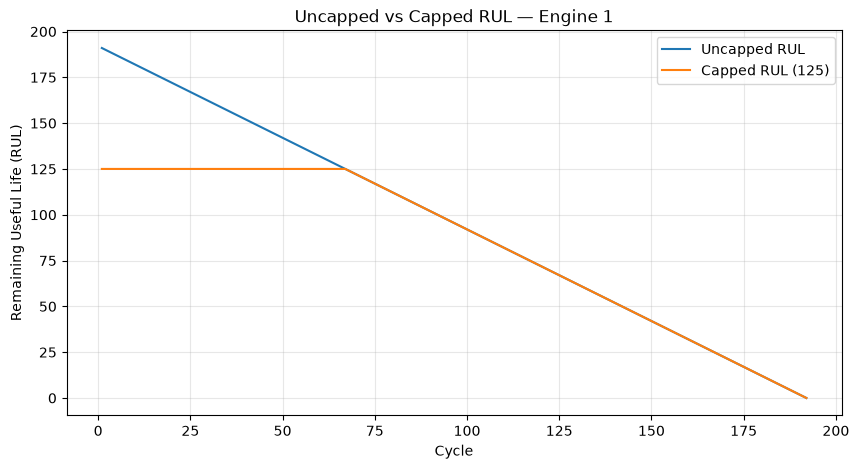

In [19]:

train1= add_rul(train,cap=None)
train2= add_rul(train, cap=125)

engine_id = 1

uncapped = train1[train1["unit"] == engine_id]
capped = train2[train2["unit"] == engine_id]

plt.figure(figsize=(10, 5))

plt.plot(uncapped["cycle"], uncapped["rul"], label="Uncapped RUL")
plt.plot(capped["cycle"], capped["rul"], label="Capped RUL (125)")

plt.xlabel("Cycle")
plt.ylabel("Remaining Useful Life (RUL)")
plt.title(f"Uncapped vs Capped RUL — Engine {engine_id}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [9]:
last_rows_test= test.groupby('unit').tail(1)
test_eval = last_rows_test.merge(rul, on="unit", how="inner")
test_eval

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,true_rul
0,1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,...,2388.06,8130.11,8.4024,0.03,393,2388,100.0,38.81,23.3552,112
1,2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,...,2388.09,8126.90,8.4505,0.03,391,2388,100.0,38.81,23.2618,98
2,3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,...,2388.14,8131.46,8.4119,0.03,395,2388,100.0,38.93,23.2740,69
3,4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,...,2388.11,8133.64,8.4634,0.03,395,2388,100.0,38.58,23.2581,82
4,5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,...,2388.15,8125.74,8.4362,0.03,394,2388,100.0,38.75,23.4117,91
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,97,-0.0006,0.0003,100.0,518.67,642.30,1590.88,1397.94,14.62,...,2388.01,8148.24,8.4110,0.03,391,2388,100.0,38.96,23.4606,137
96,97,134,0.0013,-0.0001,100.0,518.67,642.59,1582.96,1410.92,14.62,...,2388.06,8155.48,8.4500,0.03,395,2388,100.0,38.61,23.2953,82
97,98,121,0.0017,0.0001,100.0,518.67,642.68,1599.51,1415.47,14.62,...,2388.09,8146.39,8.4235,0.03,394,2388,100.0,38.76,23.3608,59
98,99,97,0.0047,-0.0000,100.0,518.67,642.00,1585.03,1397.98,14.62,...,2388.02,8150.38,8.4003,0.03,391,2388,100.0,38.95,23.3595,117


In [12]:
# constant baseline
mean_rul_uncapped = train1["rul"].mean()
mean_rul_capped = train2["rul"].mean()

print("Mean uncapped RUL:", mean_rul_uncapped)
print("Mean capped RUL:", mean_rul_capped)

n_engines = len(test_eval)

test_eval["constant_uncapped"] = np.full(
    n_engines, mean_rul_uncapped
)

test_eval["constant_capped"] = np.full(
    n_engines, mean_rul_capped
)

Mean uncapped RUL: 107.80786195530997
Mean capped RUL: 86.82928602588338


In [20]:
# age based baseline

mean_lifetime = train.groupby("unit")["cycle"].max().mean()

print("Mean training lifetime:", mean_lifetime)

test_eval["age_based"] = np.maximum(
    mean_lifetime - test_eval["cycle"],
    0
)
test_eval["age_based_capped"] = test_eval["age_based"].clip(upper=125)

Mean training lifetime: 206.31


In [21]:

y_true = test_eval["true_rul"]

predictions = {
    "Constant (uncapped mean)": test_eval["constant_uncapped"],
    "Constant (capped mean)": test_eval["constant_capped"],
    "Age-based (uncapped)": test_eval["age_based"],
     "Age-based (capped)": test_eval["age_based_capped"]

}

results = []

for name, y_pred in predictions.items():
    results.append({
        "Baseline": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df)

,Baseline,MAE,RMSE
3,Age-based (capped),28.013100,36.793155
2,Age-based (uncapped),32.052000,40.195922
1,Constant (capped mean),35.900000,43.067036
0,Constant (uncapped mean),40.879302,52.624858
